> STATUS: ATUAL — execução final COM, BEST época 3.
> Revisão editorial em 30/10/2026: somente apresentação de resultados existentes; este notebook não foi reexecutado nesta revisão.
> Consulte o [guia oficial](../../../GUIA_NOTEBOOKS_RESULTADOS.md). Os notebooks 03/04 contêm chamadas de inferência; seus outputs estão preservados e não devem ser reexecutados nesta etapa editorial.


In [1]:
# [celula injetada pelo executor] redireciona config para a politica shared-extrasystoles-bbb-v1
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))
import config
config.CLASSIFICATION_POLICY = "shared-extrasystoles-bbb-v1"
config.MITBIH_PROCESSED_FILE = config.PROCESSED_DIR / "mitbih_shared-extrasystoles-bbb-v1.npz"
config.LUDB_PROCESSED_FILE = config.PROCESSED_DIR / "ludb_shared-extrasystoles-bbb-v1.npz"


# 03 — Análise pós-treino (MIT-BIH)

Análises do modelo produzido por `src/train_cnn.py`. Tudo aqui usa **apenas
o MIT-BIH**, com o `StratifiedGroupKFold` e o manifesto por sujeito gravados
no checkpoint. O teste independente no LUDB está no notebook
`04_teste_ludb.ipynb`.

Os artefatos desta execução já estão presentes no pacote. Não é necessário executar o pipeline para consultar estes outputs; veja o guia oficial.

In [2]:

import matplotlib.pyplot as plt
import numpy as np

import sys
from pathlib import Path

# O codigo do projeto vive em src/ (nao ha pacote instalavel).
sys.path.insert(0, str(Path.cwd().parent / "src"))
import config
import classification
import beat_io
import test_ludb as metrics

import model_gradcam as mg

RUN_DIR = config.MODELS_DIR / "cnn1d_mitbih_shared-extrasystoles-bbb-v1"

modelo, ckpt = mg.load_checkpoint(RUN_DIR / mg.CHECKPOINT_NAME, expected_policy=config.CLASSIFICATION_POLICY)
info = ckpt["info"]
limiar = float(ckpt["threshold"])  # fixo, não otimizado

print(f"criado em    : {info['criado_em']}")
print(f"torch        : {info['torch']}")
print(f"parâmetros   : {info['n_parametros']}")
print(f"arquitetura  : {info['arquitetura']}")
print(f"limiar       : {limiar:.4f} (fixo em todo o projeto)")

criado em    : 2026-10-30T02:20:00+00:00
torch        : 2.11.0+cu128
parâmetros   : 121633
arquitetura  : CNN1D_Arritmia
limiar       : 0.5000 (fixo em todo o projeto)


## 1. O que o checkpoint carrega consigo

O `.pt` é autocontido: além dos pesos, guarda os hiperparâmetros da
arquitetura, a divisão usada e todas as métricas. É o que permite reproduzir a
análise sem o ambiente de treino.

O limiar de decisão **não é otimizado** neste projeto — é sempre
`config.DEFAULT_THRESHOLD` (0.5), o mesmo valor em treino, validação e no teste
no LUDB. Escolhê-lo por conjunto abriria uma forma indireta de ajustar o
modelo aos dados de teste.

In [3]:
split = info["split"]
for nome, dados_split in split.items():
    print(
        f"{nome:<10} {dados_split['n_batimentos']:>6} batimentos | "
        f"{dados_split['n_sujeitos']:>2} sujeitos | "
        f"prevalência classe 1: {dados_split['prevalencia_classe_1']:.4f}"
    )

print("\nregistros de validação:")
print(" ", " ".join(split["validacao"]["pacientes"]))

# A interseção vazia é o requisito por sujeito — inclui o vínculo 201/202.
comuns = set(split["treino"]["sujeitos"]) & set(split["validacao"]["sujeitos"])
print(f"\nsujeitos em ambos os conjuntos: {comuns or 'nenhum'}")

treino      74332 batimentos | 32 sujeitos | prevalência classe 1: 0.1837
validacao   25110 batimentos | 11 sujeitos | prevalência classe 1: 0.4487

registros de validação:
  100 103 109 118 119 124 201 202 214 220 221 231

sujeitos em ambos os conjuntos: nenhum


## 2. Curvas de treino

`history.csv` traz uma linha por época. O modelo usa os pesos da **última**
época — não há seleção de época por validação. A validação é inter-paciente e
por isso oscila bastante ao longo do treino.

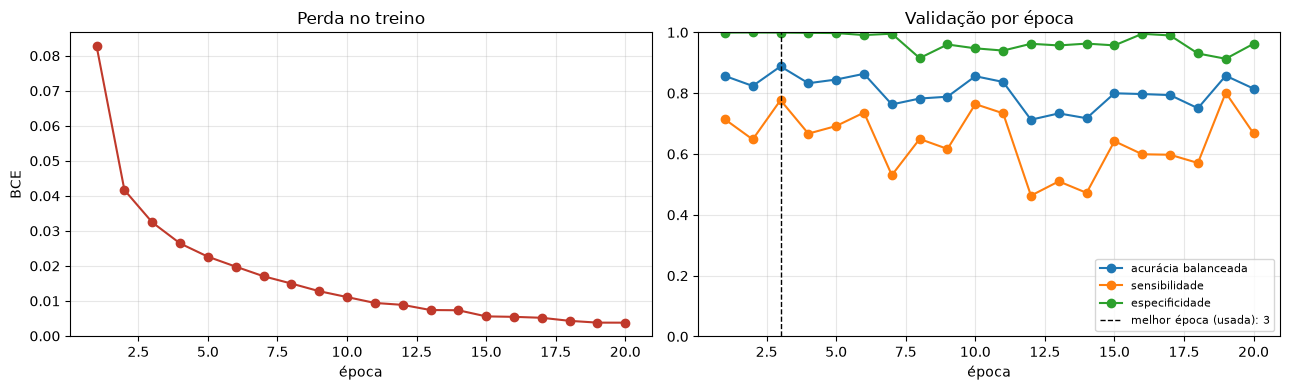

In [4]:
historico = np.genfromtxt(
    RUN_DIR / mg.HISTORY_NAME, delimiter=",", names=True
)
epocas = historico["epoca"]

fig, eixos = plt.subplots(1, 2, figsize=(13, 4))

eixos[0].plot(epocas, historico["loss_treino"], marker="o", color="#c0392b")
eixos[0].set_title("Perda no treino")
eixos[0].set_xlabel("época")
eixos[0].set_ylabel("BCE")

for chave, rotulo in [
    ("val_acuracia_balanceada", "acurácia balanceada"),
    ("val_sensibilidade", "sensibilidade"),
    ("val_especificidade", "especificidade"),
]:
    eixos[1].plot(epocas, historico[chave], marker="o", label=rotulo)
eixos[1].axvline(info["checkpoint_epoch"], color="k", ls="--", lw=1, label=f"melhor época (usada): {info['checkpoint_epoch']}")
eixos[1].set_title("Validação por época")
eixos[1].set_xlabel("época")
eixos[1].set_ylim(0, 1)
eixos[1].legend(fontsize=8)

for eixo in eixos:
    eixo.grid(alpha=0.3)
fig.tight_layout()
plt.show()

## 3. Predições na validação

Usamos os índices de validação gravados no checkpoint (`info['val_idx']`) e
rodamos o modelo congelado sobre eles.

In [5]:
dados = beat_io.load_beat_dataset(config.MITBIH_PROCESSED_FILE)
X = dados["series"]
y = dados["labels"].astype(int)
simbolos = dados["simbolos"]
pacientes = dados["pacientes"]

val_idx = np.array(info["val_idx"])
scores = mg.predict_scores(modelo, X[val_idx])
y_val = y[val_idx]
m_val = metrics.binary_metrics(y_val, scores, limiar)

print(metrics.formata_metricas("VALIDAÇÃO", m_val))

[VALIDAÇÃO] n=25110  limiar=0.50
  acuracia            : 0.8995
  acuracia balanceada : 0.8881
  sensibilidade (rec) : 0.7770
  especificidade      : 0.9991
  precisao            : 0.9986
  f1                  : 0.8740
  auc-roc             : 0.9601
  confusao            : tp=8755 fn=2512 tn=13831 fp=12


## 4. Sensibilidade ao limiar (apenas informativo)

O projeto **não otimiza** o limiar — ele é sempre 0.5. O gráfico abaixo só
mostra o que aconteceria se fosse diferente, para deixar claro o motivo da
escolha: em 0.5 a acurácia balanceada já está muito perto do pico da curva, e
mexer nele trocaria sensibilidade por especificidade sem ganho real. Nenhum
valor lido aqui é usado em nenhuma parte do pipeline.

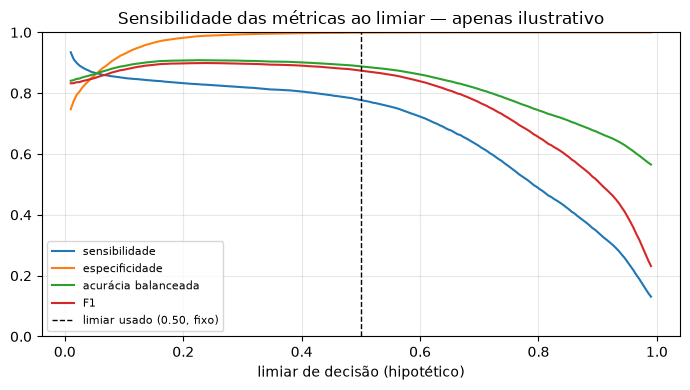

In [6]:
grade = np.linspace(0.01, 0.99, 199)
curvas = np.array([
    [
        m["sensibilidade"],
        m["especificidade"],
        m["acuracia_balanceada"],
        m["f1"],
    ]
    for m in (metrics.binary_metrics(y_val, scores, float(t)) for t in grade)
])

fig, eixo = plt.subplots(figsize=(7, 4))
for coluna, rotulo in enumerate(
    ["sensibilidade", "especificidade", "acurácia balanceada", "F1"]
):
    eixo.plot(grade, curvas[:, coluna], label=rotulo)
eixo.axvline(limiar, color="k", ls="--", lw=1, label=f"limiar usado ({limiar:.2f}, fixo)")
eixo.set_xlabel("limiar de decisão (hipotético)")
eixo.set_ylim(0, 1)
eixo.grid(alpha=0.3)
eixo.legend(fontsize=8)
eixo.set_title("Sensibilidade das métricas ao limiar — apenas ilustrativo")
fig.tight_layout()
plt.show()

## 5. Matriz de confusão e separação dos scores

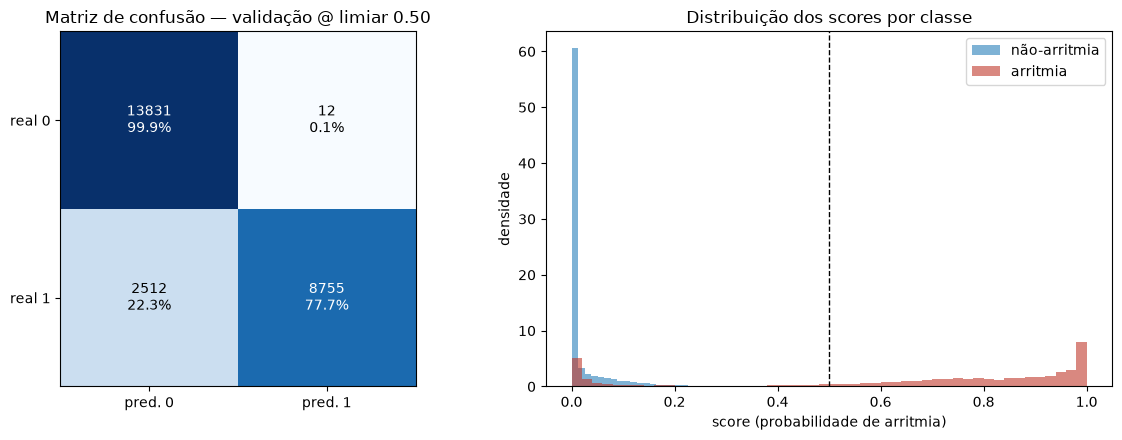

In [7]:
cm = np.array([[m_val["tn"], m_val["fp"]], [m_val["fn"], m_val["tp"]]])

fig, eixos = plt.subplots(1, 2, figsize=(12, 4.5))

eixos[0].imshow(cm / cm.sum(axis=1, keepdims=True), cmap="Blues", vmin=0, vmax=1)
for i in range(2):
    for j in range(2):
        eixos[0].text(
            j, i, f"{cm[i, j]}\n{cm[i, j] / cm[i].sum():.1%}",
            ha="center", va="center",
            color="white" if cm[i, j] / cm[i].sum() > 0.5 else "black",
        )
eixos[0].set_xticks([0, 1], ["pred. 0", "pred. 1"])
eixos[0].set_yticks([0, 1], ["real 0", "real 1"])
eixos[0].set_title(f"Matriz de confusão — validação @ limiar {limiar:.2f}")

for classe, cor, rotulo in [(0, "#2980b9", "não-arritmia"), (1, "#c0392b", "arritmia")]:
    eixos[1].hist(
        scores[y_val == classe], bins=50, alpha=0.6, color=cor,
        label=rotulo, density=True,
    )
eixos[1].axvline(limiar, color="k", ls="--", lw=1)
eixos[1].set_xlabel("score (probabilidade de arritmia)")
eixos[1].set_ylabel("densidade")
eixos[1].legend()
eixos[1].set_title("Distribuição dos scores por classe")

fig.tight_layout()
plt.show()

## 6. Análise de falhas por tipo de batimento

O campo `simbolos` preserva o símbolo original do MIT-BIH, então dá para ver
**quais arritmias** o modelo perde. É essa quebra que a Etapa 4 vai cruzar com
a fidelidade do Grad-CAM: um tipo com baixa taxa de acerto e Grad-CAM disperso
conta uma história diferente de um com baixa taxa de acerto e Grad-CAM focado
no QRS.

[validação por símbolo] desempenho por grupo
  grupo                             n  classe   acerto   score
  N                             13843       0   0.9991  0.0219
  R                              4948       1   0.6198  0.5656
  L                              4492       1   0.9114  0.7300
  V                              1417       1   0.9555  0.9541
  A                               294       1   0.4796  0.4740
  a                               116       1   0.8534  0.7734


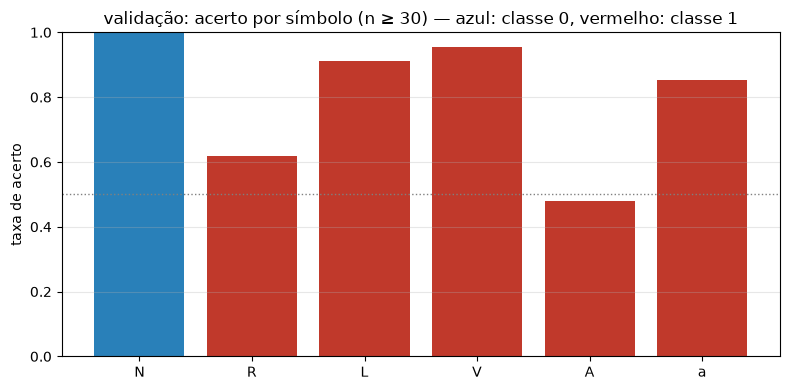

In [8]:
por_simbolo = metrics.por_grupo(y_val, scores, simbolos[val_idx], threshold=limiar)
print(metrics.formata_por_grupo("validação por símbolo", por_simbolo))

fig, eixo = plt.subplots(figsize=(8, 4))
relevantes = [linha for linha in por_simbolo if linha["n"] >= 30]
nomes = [linha["grupo"] for linha in relevantes]
taxas = [linha["taxa_acerto"] for linha in relevantes]
cores = ["#2980b9" if linha["classe_verdadeira"] == 0 else "#c0392b" for linha in relevantes]
eixo.bar(nomes, taxas, color=cores)
eixo.axhline(0.5, color="gray", ls=":", lw=1)
eixo.set_ylim(0, 1)
eixo.set_ylabel("taxa de acerto")
eixo.set_title("validação: acerto por símbolo (n ≥ 30) — azul: classe 0, vermelho: classe 1")
eixo.grid(alpha=0.3, axis="y")
fig.tight_layout()
plt.show()

## 7. Variação entre pacientes

A média esconde o quanto o desempenho depende do indivíduo — o principal motivo
de a divisão ser inter-paciente. Os registros com pior acerto são candidatos
naturais à inspeção qualitativa da Etapa 5.

acerto por registro: mediana 0.9792 | mín 0.0272 | máx 1.0000

5 registros com pior acerto:
  registro 124   n= 1579 acerto=0.0272 score médio=0.0524
  registro 118   n= 2277 acerto=0.8410 score médio=0.7514
  registro 214   n= 2257 acerto=0.8689 score médio=0.7859
  registro 109   n= 2529 acerto=0.9411 score médio=0.6932
  registro 220   n= 2046 acerto=0.9677 score médio=0.0162


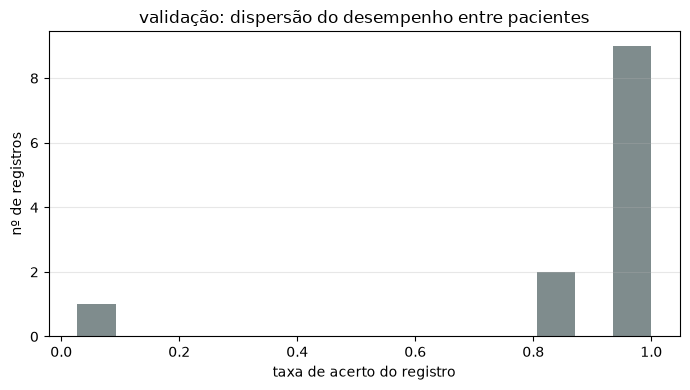

In [9]:
por_paciente = metrics.por_grupo(y_val, scores, pacientes[val_idx], threshold=limiar)
taxas = np.array([linha["taxa_acerto"] for linha in por_paciente])

print(f"acerto por registro: mediana {np.median(taxas):.4f} | "
      f"mín {taxas.min():.4f} | máx {taxas.max():.4f}")
print("\n5 registros com pior acerto:")
for linha in sorted(por_paciente, key=lambda linha: linha["taxa_acerto"])[:5]:
    print(
        f"  registro {linha['grupo']:<5} n={linha['n']:>5} "
        f"acerto={linha['taxa_acerto']:.4f} score médio={linha['score_medio']:.4f}"
    )

fig, eixo = plt.subplots(figsize=(7, 4))
eixo.hist(taxas, bins=15, color="#7f8c8d")
eixo.set_xlabel("taxa de acerto do registro")
eixo.set_ylabel("nº de registros")
eixo.set_title("validação: dispersão do desempenho entre pacientes")
eixo.grid(alpha=0.3, axis="y")
fig.tight_layout()
plt.show()

## 8. Batimentos que o modelo erra

Média e desvio dos batimentos por quadrante da matriz de confusão. Os falsos
negativos são o grupo mais relevante para a Etapa 4: se o Grad-CAM neles ainda
apontar QRS e T, o erro é de decisão, não de foco.

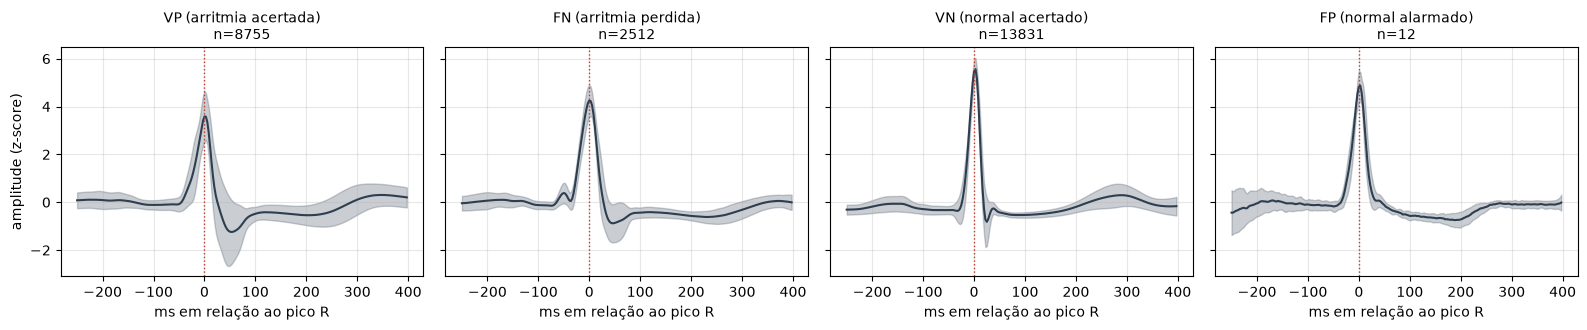

In [10]:
y_pred = (scores >= limiar).astype(int)
quadrantes = {
    "VP (arritmia acertada)": (y_val == 1) & (y_pred == 1),
    "FN (arritmia perdida)": (y_val == 1) & (y_pred == 0),
    "VN (normal acertado)": (y_val == 0) & (y_pred == 0),
    "FP (normal alarmado)": (y_val == 0) & (y_pred == 1),
}

tempo = (np.arange(X.shape[1]) - config.WINDOW_LEFT) / config.TARGET_FS * 1000
fig, eixos = plt.subplots(1, 4, figsize=(16, 3.4), sharey=True)
for eixo, (titulo, mascara) in zip(eixos, quadrantes.items()):
    grupo = X[val_idx][mascara]
    media = grupo.mean(axis=0)
    desvio = grupo.std(axis=0)
    eixo.plot(tempo, media, color="#2c3e50")
    eixo.fill_between(tempo, media - desvio, media + desvio, alpha=0.25, color="#2c3e50")
    eixo.axvline(0, color="#c0392b", ls=":", lw=1)
    eixo.set_title(f"{titulo}\nn={mascara.sum()}", fontsize=10)
    eixo.set_xlabel("ms em relação ao pico R")
    eixo.grid(alpha=0.3)
eixos[0].set_ylabel("amplitude (z-score)")
fig.tight_layout()
plt.show()

## 9. Próximo passo

O modelo está validado dentro do MIT-BIH. O teste independente — base
diferente, população diferente, anotações clínicas de P/QRS/T — está em
`04_teste_ludb.ipynb`, e é sobre aquele conjunto que a métrica de fidelidade do
Grad-CAM (Etapa 4) será calculada.